# Analisis Spasial & Temporal Data Curah Hujan CHIRPS (NetCDF)
Notebook ini digunakan untuk membaca, menggabungkan, dan menganalisis dataset NetCDF (`.nc`) CHIRPS dilengkapi overlay batas kecamatan Kebumen (`33.05_kecamatan.geojson`) serta visualisasi spasial bulanan dengan `Discrete Boundary Normalization`.

### Fitur Utama:
- **Dual Compatibility (Lokal & Kaggle):** Otomatis mendeteksi dataset Kaggle di `/kaggle/input/datasets/jerismeteo/gee-chirps-kebumen/` dan `/kaggle/input/datasets/jerismeteo/projek-downscale/`.
- **Multi-File NetCDF Merging:** Menggabungkan file harian/bulanan CHIRPS multi-tahun secara efisien dengan `xarray`.
- **Areal Mean Time Series:** Analisis deret waktu curah hujan harian, bulanan, dan tahunan.
- **Klimatologi & Peta Spasial:** Analisis pola musiman dan visualisasi spasial dengan overlay batas wilayah kecamatan.

In [1]:
import os
import glob
import xarray as xr
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = "DejaVu Sans"
plt.rcParams['font.family'] = "sans-serif"

# ==========================================
# 0. PENGATURAN PATH DUAL-ENVIRONMENT (Lokal & Kaggle)
# ==========================================
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    # Path Data CHIRPS di Kaggle
    kaggle_chirps_dir = Path("/kaggle/input/datasets/jerismeteo/gee-chirps-kebumen")
    if (kaggle_chirps_dir / "data/chirps").exists():
        data_dir = kaggle_chirps_dir / "data/chirps"
    elif kaggle_chirps_dir.exists():
        data_dir = kaggle_chirps_dir
    else:
        found_chirps = glob.glob("/kaggle/input/**/chirps*", recursive=True)
        data_dir = Path(found_chirps[0]) if found_chirps else Path("data/chirps")
        
    # Path GeoJSON di Kaggle
    kaggle_geojson = Path("/kaggle/input/datasets/jerismeteo/projek-downscale/33.05_kecamatan.geojson")
    if kaggle_geojson.exists():
        geojson_path = str(kaggle_geojson)
    else:
        found_geo = glob.glob("/kaggle/input/**/33.05_kecamatan.geojson", recursive=True)
        geojson_path = found_geo[0] if found_geo else "33.05_kecamatan.geojson"
        
    out_dir = Path("/kaggle/working/chirps_bulanan")
else:
    # Path Lokal
    data_dir = Path("data/chirps")
    geojson_path = "33.05_kecamatan.geojson"
    out_dir = Path("chirps_bulanan")

out_dir.mkdir(parents=True, exist_ok=True)
print(f"📌 Direktori Data CHIRPS : {data_dir}")
print(f"📌 Lokasi File GeoJSON   : {geojson_path}")
print(f"📌 Direktori Output Peta : {out_dir}")

📌 Direktori Data CHIRPS : /kaggle/input/datasets/jerismeteo/gee-chirps-kebumen/data/chirps
📌 Lokasi File GeoJSON   : /kaggle/input/datasets/jerismeteo/projek-downscale/33.05_kecamatan.geojson
📌 Direktori Output Peta : /kaggle/working/chirps_bulanan


## 1. Memuat & Menggabungkan File NetCDF CHIRPS
Menggunakan `xarray.open_mfdataset` untuk memuat semua file `.nc` dari subfolder CHIRPS secara otomatis dan efisien.

In [2]:
# Cari seluruh file .nc secara rekursif
nc_files = sorted(list(data_dir.glob("**/*.nc")))
print(f"Total file NetCDF CHIRPS ditemukan: {len(nc_files)}")

if len(nc_files) == 0:
    raise FileNotFoundError(f"Tidak ada file .nc ditemukan di direktori: {data_dir}")

# Buka seluruh dataset menggunakan xarray
ds = xr.open_mfdataset(nc_files, combine='by_coords')
print("\n--- Informasi Dataset CHIRPS ---")
print(ds)

Total file NetCDF CHIRPS ditemukan: 318


/tmp/ipykernel_16/3387907817.py:9: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(nc_files, combine='by_coords')



--- Informasi Dataset CHIRPS ---
<xarray.Dataset> Size: 4MB
Dimensions:        (time: 9678, y: 9, x: 10)
Coordinates:
  * time           (time) datetime64[ns] 77kB 2000-01-01 ... 2026-06-30
  * y              (y) float64 72B -7.425 -7.475 -7.525 ... -7.725 -7.775 -7.825
  * x              (x) float64 80B 109.4 109.4 109.5 109.5 ... 109.7 109.8 109.8
Data variables:
    spatial_ref    (time) int64 77kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    precipitation  (time, y, x) float32 3MB dask.array<chunksize=(31, 9, 10), meta=np.ndarray>


## 2. Memuat Peta Vektor Wilayah (GeoJSON Kecamatan Kebumen)
Membaca file GeoJSON `33.05_kecamatan.geojson` untuk batas administratif dan label nama kecamatan.

In [3]:
gdf_kec = gpd.read_file(geojson_path)
if gdf_kec.crs != "EPSG:4326":
    gdf_kec = gdf_kec.to_crs("EPSG:4326")

print(f"Berhasil memuat GeoJSON: {len(gdf_kec)} Kecamatan di Kebumen")
gdf_kec.head(26)

Berhasil memuat GeoJSON: 26 Kecamatan di Kebumen


,kd_propinsi,kd_dati2,kd_kecamatan,nm_kecamatan,geometry
0,33,05,001,Ayah,"MULTIPOLYGON Z (((109.41096 -7.77624 0, 109.41..."
1,33,05,002,Buayan,"MULTIPOLYGON Z (((109.46888 -7.75906 0, 109.46..."
2,33,05,003,Puring,"MULTIPOLYGON Z (((109.5242 -7.76568 0, 109.524..."
3,33,05,004,Petanahan,"MULTIPOLYGON Z (((109.59079 -7.77741 0, 109.59..."
4,33,05,005,Klirong,"MULTIPOLYGON Z (((109.64391 -7.77253 0, 109.64..."
5,33,05,006,Buluspesantren,"MULTIPOLYGON Z (((109.66965 -7.79333 0, 109.66..."
6,33,05,007,Ambal,"MULTIPOLYGON Z (((109.71173 -7.80303 0, 109.71..."
7,33,05,008,Mirit,"MULTIPOLYGON Z (((109.79535 -7.82364 0, 109.79..."
8,33,05,009,Prembun,"MULTIPOLYGON Z (((109.80302 -7.72594 0, 109.80..."
9,33,05,010,Kutowinangun,"MULTIPOLYGON Z (((109.72402 -7.72604 0, 109.72..."


## 3. Ekstraksi Deret Waktu Rata-rata Wilayah (Areal Mean Time Series)
Merata-ratakan nilai curah hujan di seluruh grid spasial (dimensi spasial `x`, `y` atau `lat`, `lon`).

In [4]:
# Deteksi dimensi spasial secara dinamis (misal x,y atau lat,lon)
spatial_dims = [dim for dim in ds['precipitation'].dims if dim != 'time']
da_areal_mean = ds['precipitation'].mean(dim=spatial_dims).to_series()
df_base = pd.DataFrame({'rainfall': da_areal_mean})
df_base.index.name = 'DateTime'

print("Statistik Data Basis:")
print(df_base.describe())

Statistik Data Basis:
          rainfall
count  9678.000000
mean      9.063567
std      12.823576
min       0.000000
25%       0.588811
50%       3.382544
75%      12.969018
max     128.704239


## 4. Agregasi Waktu (Standar WMO - SUM)
Akumulasi volume curah hujan ke skala Harian (Daily), Bulanan (Monthly), dan Tahunan (Annual).

In [5]:
# Jika data per-jam/sub-harian diakumulasikan ke harian
if pd.infer_freq(df_base.index) not in ['D', '1D'] and len(df_base) > len(df_base.resample('D').sum()):
    df_daily = df_base.resample('D').sum()
else:
    df_daily = df_base

df_monthly = df_daily.resample('ME').sum()
df_annual = df_daily.resample('YE').sum()

print(f"Total hari   : {len(df_daily)}")
print(f"Total bulan  : {len(df_monthly)}")
print(f"Total tahun  : {len(df_annual)}")

Total hari   : 9678
Total bulan  : 318
Total tahun  : 27


## 5. Visualisasi Time Series Curah Hujan Harian & Bulanan

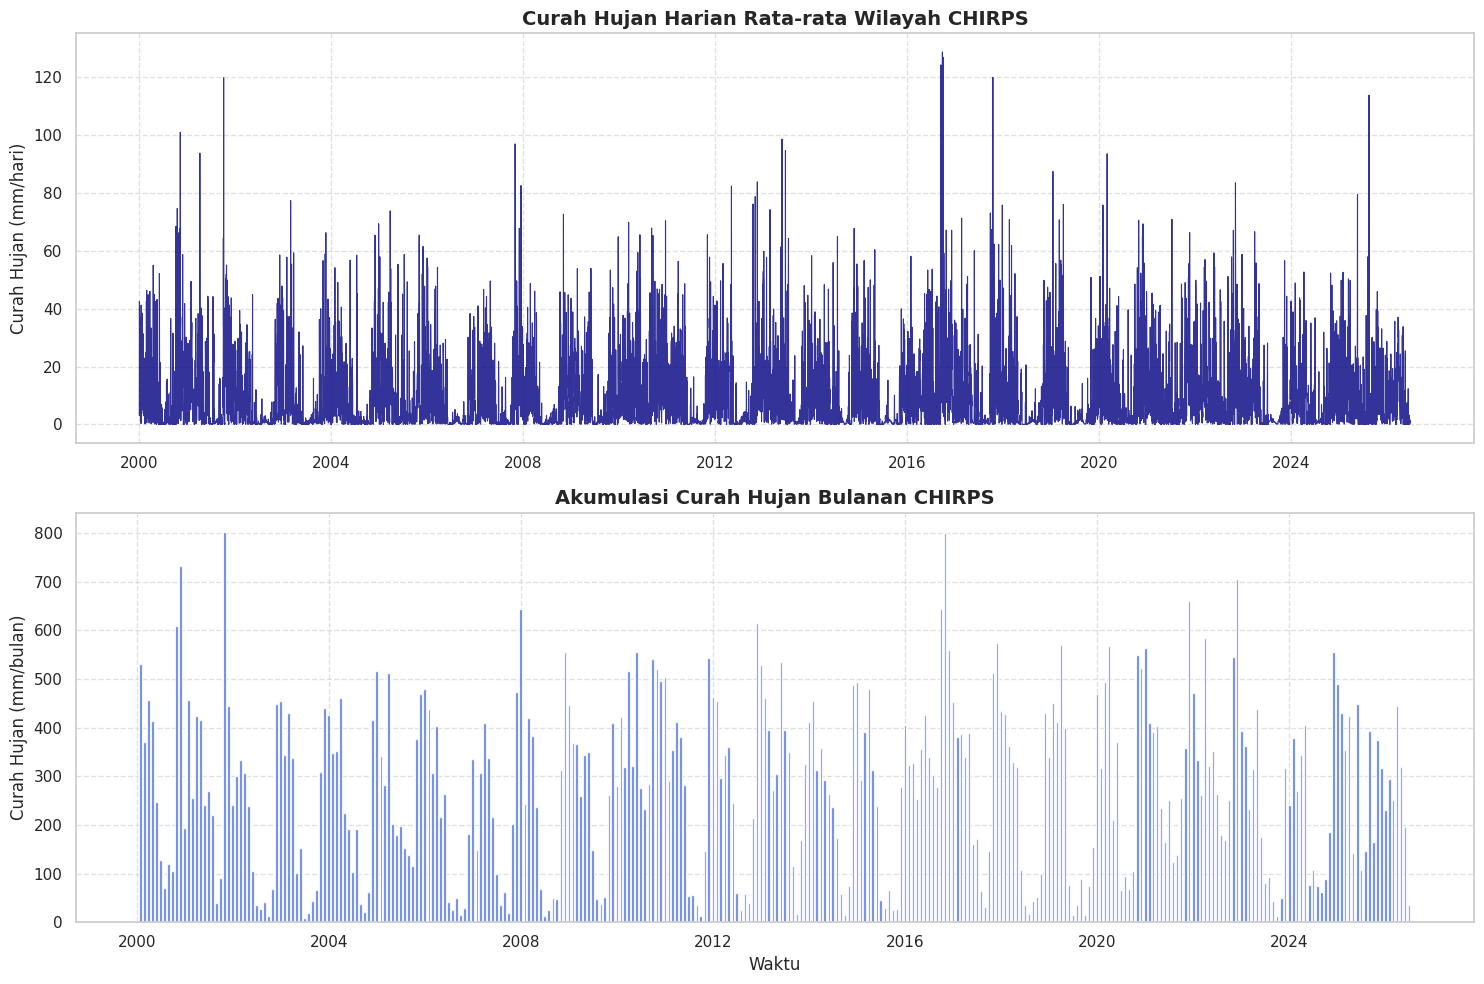

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=False)

# Daily plot
axes[0].plot(df_daily.index, df_daily['rainfall'], color='navy', linewidth=0.8, alpha=0.8)
axes[0].set_title("Curah Hujan Harian Rata-rata Wilayah CHIRPS", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Curah Hujan (mm/hari)", fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Monthly plot
axes[1].bar(df_monthly.index, df_monthly['rainfall'], color='royalblue', width=20, alpha=0.85)
axes[1].set_title("Akumulasi Curah Hujan Bulanan CHIRPS", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Curah Hujan (mm/bulan)", fontsize=12)
axes[1].set_xlabel("Waktu", fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Visualisasi Distribusi Spasial Keseluruhan dengan Overlay Peta Kecamatan GeoJSON
Memetakan sebaran curah hujan raster dan menimpa (overlay) garis batas kecamatan dari `33.05_kecamatan.geojson`.

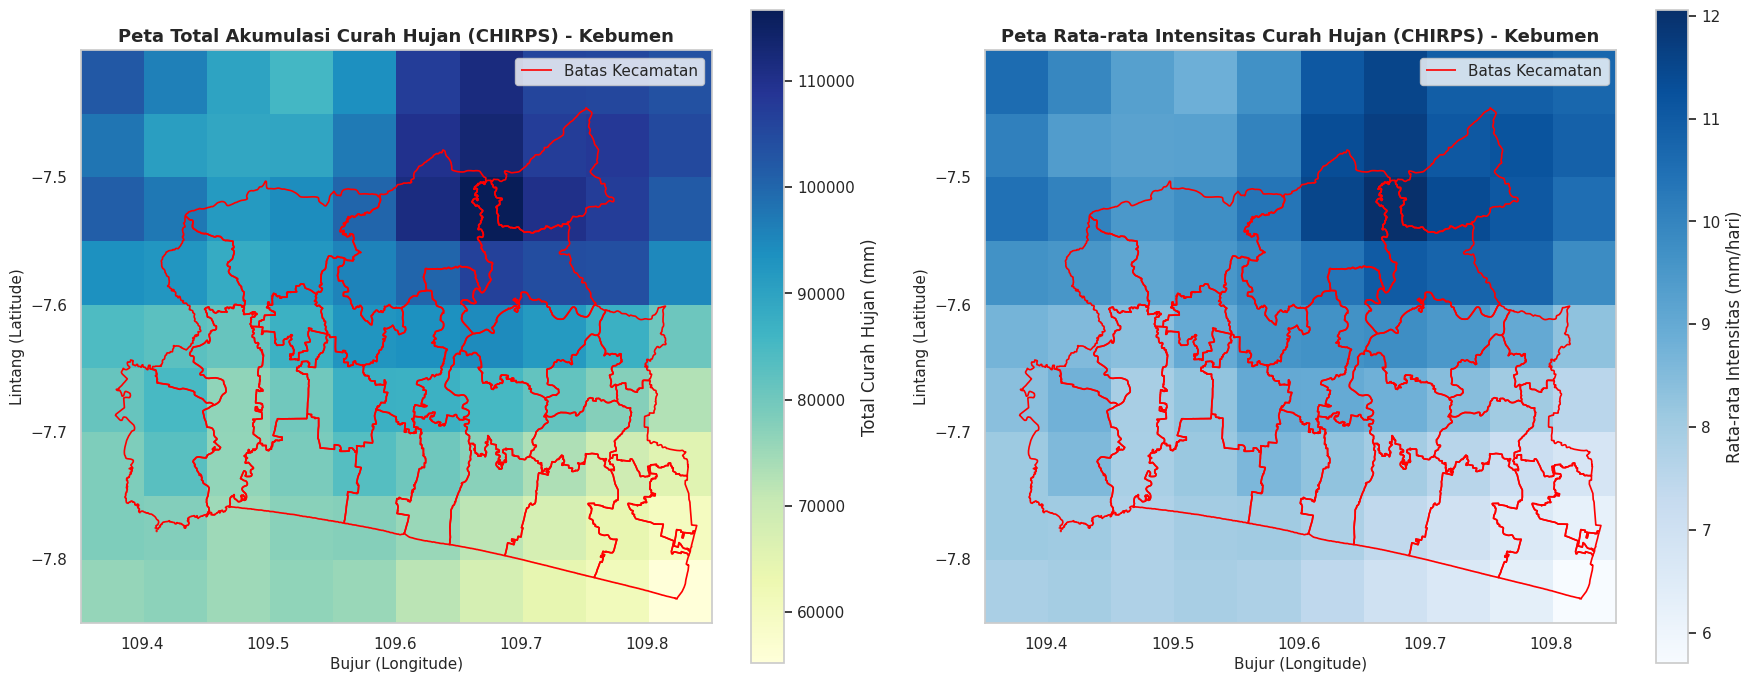

In [7]:
# Hitung total akumulasi & rata-rata curah hujan secara spasial
spatial_total = ds['precipitation'].sum(dim='time')
spatial_mean = ds['precipitation'].mean(dim='time')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Peta Total + Overlay GeoJSON
spatial_total.plot(ax=axes[0], cmap='YlGnBu', cbar_kwargs={'label': 'Total Curah Hujan (mm)'})
gdf_kec.boundary.plot(ax=axes[0], color='red', linewidth=1.2, label='Batas Kecamatan')
axes[0].set_title("Peta Total Akumulasi Curah Hujan (CHIRPS) - Kebumen", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Bujur (Longitude)", fontsize=11)
axes[0].set_ylabel("Lintang (Latitude)", fontsize=11)
axes[0].legend(loc='upper right')

# Peta Rata-rata + Overlay GeoJSON
spatial_mean.plot(ax=axes[1], cmap='Blues', cbar_kwargs={'label': 'Rata-rata Intensitas (mm/hari)'})
gdf_kec.boundary.plot(ax=axes[1], color='red', linewidth=1.2, label='Batas Kecamatan')
axes[1].set_title("Peta Rata-rata Intensitas Curah Hujan (CHIRPS) - Kebumen", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Bujur (Longitude)", fontsize=11)
axes[1].set_ylabel("Lintang (Latitude)", fontsize=11)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 7. Pola Klimatologi Bulanan
Melihat profil rata-rata curah hujan untuk tiap bulan (Januari - Desember) selama periode pengamatan.

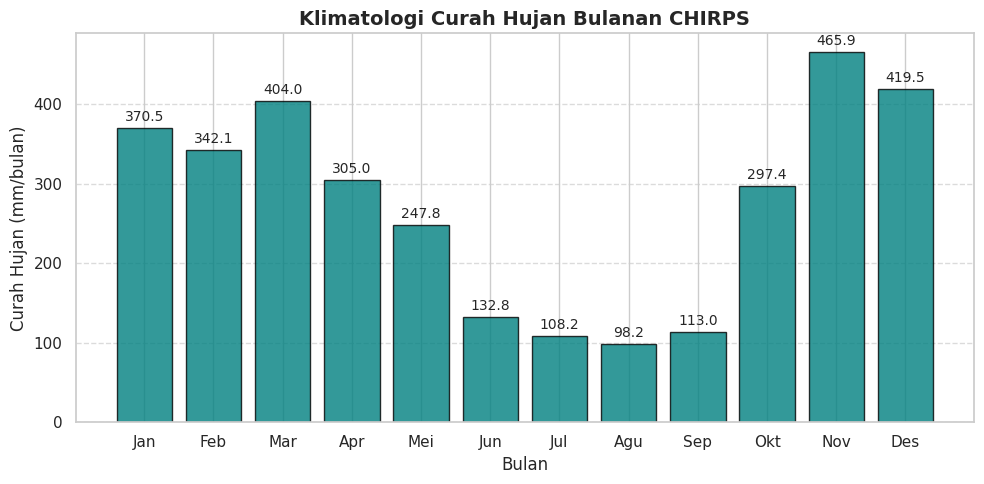

In [8]:
monthly_climatology = df_monthly.groupby(df_monthly.index.month).mean()

plt.figure(figsize=(10, 5))
bars = plt.bar(monthly_climatology.index, monthly_climatology['rainfall'], color='teal', alpha=0.8, edgecolor='black')
plt.title("Klimatologi Curah Hujan Bulanan CHIRPS", fontsize=14, fontweight='bold')
plt.xlabel("Bulan", fontsize=12)
plt.ylabel("Curah Hujan (mm/bulan)", fontsize=12)
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Nilai di atas bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f'{yval:.1f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## 8. Visualisasi Spasial Bulanan dengan Discrete Boundary Normalization
Menghasilkan peta distribusi spasial curah hujan per bulan berbasis interval diskret ilmiah (`BoundaryNorm`), label nama kecamatan Kebumen, dan colorbar horizontal di bawah.

Memproses visualisasi bulanan untuk Tahun: 2026


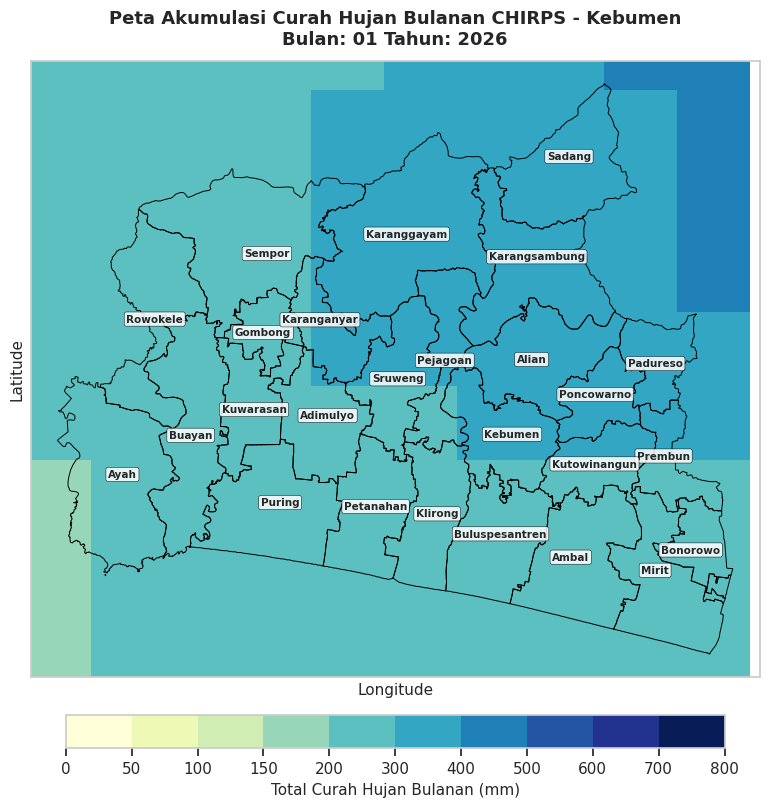

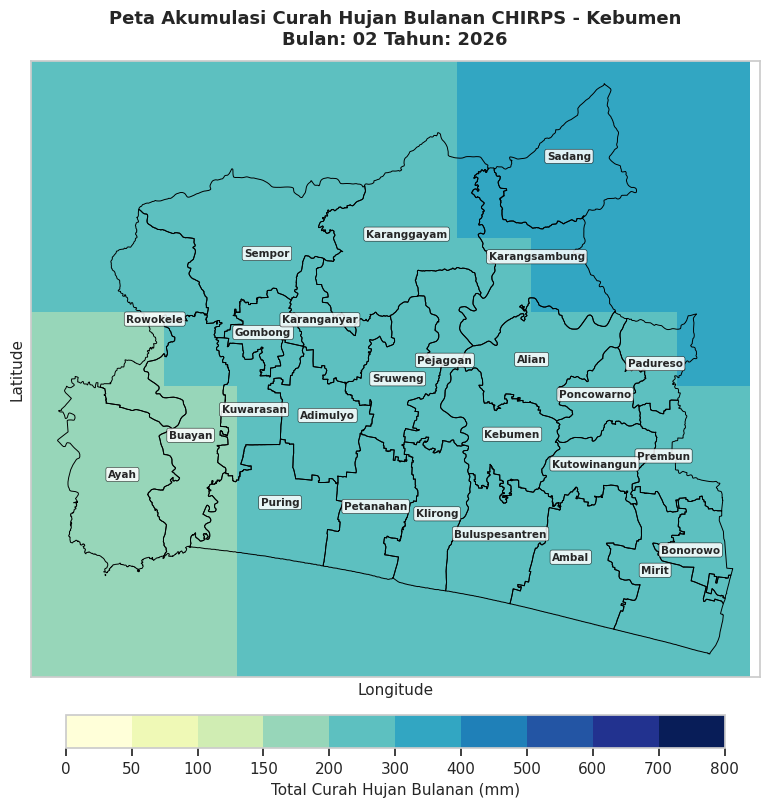

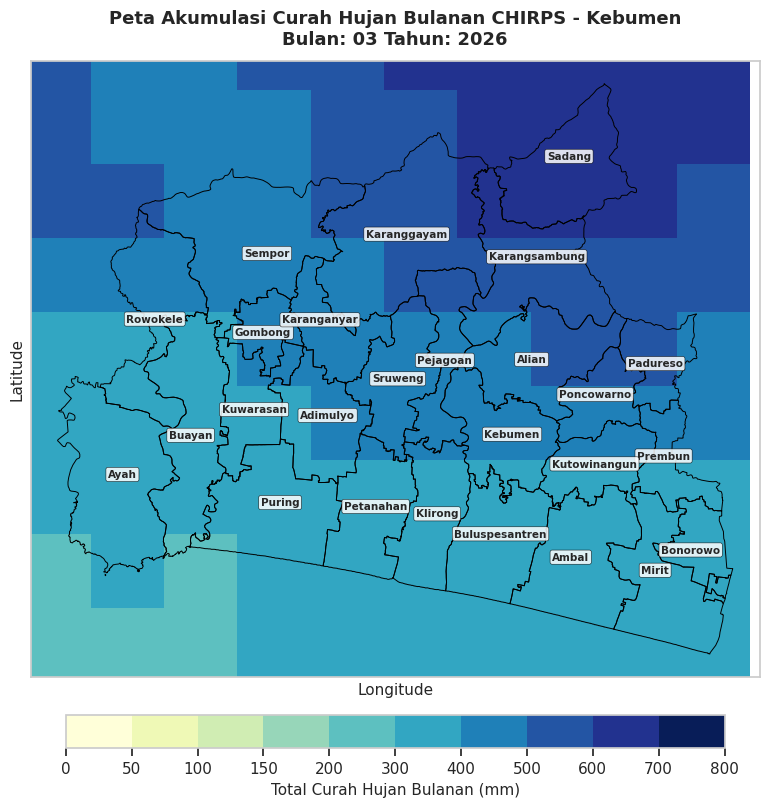

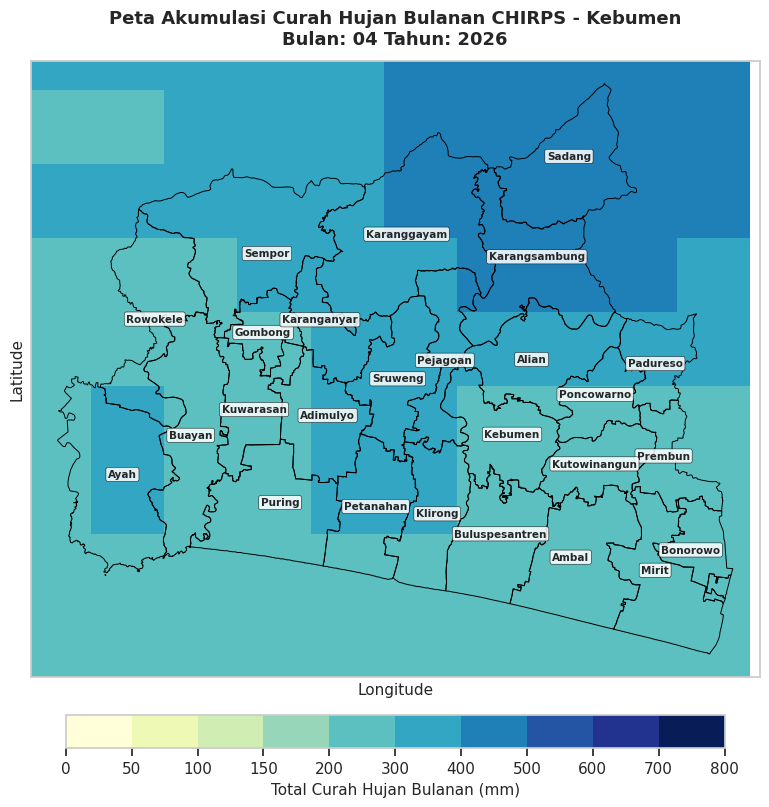

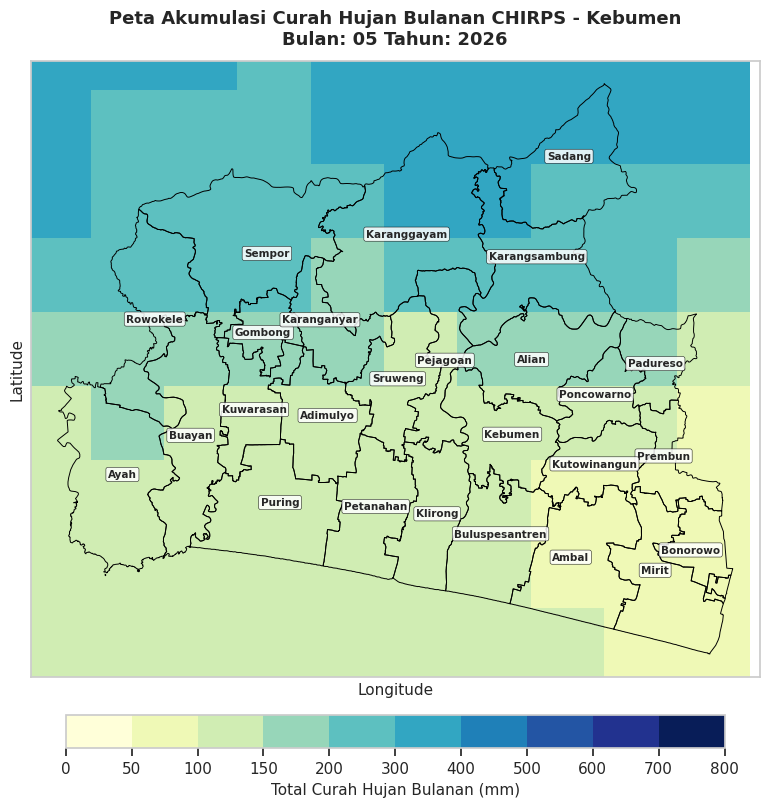

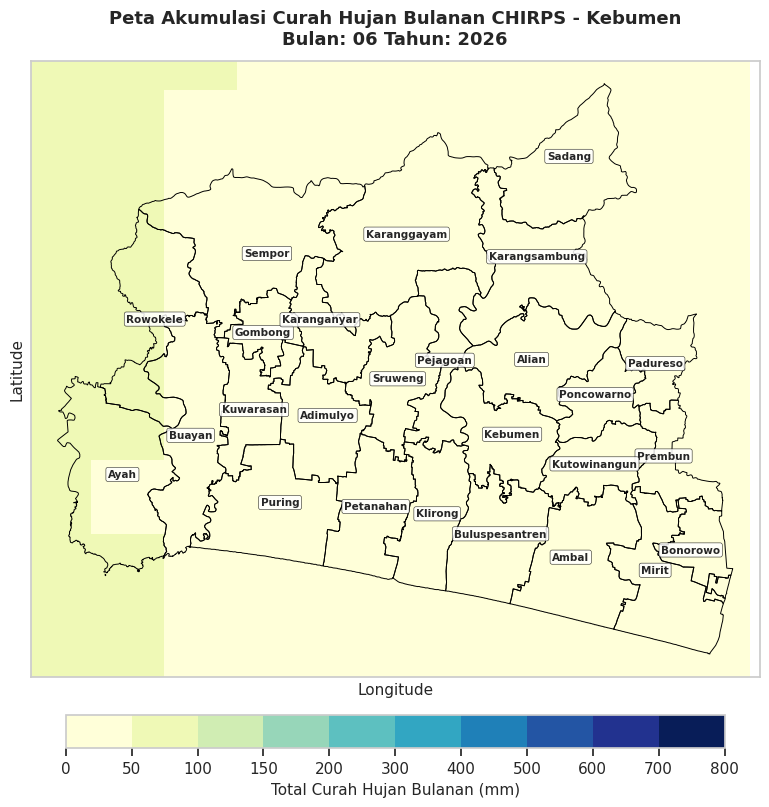

Seluruh peta diskret bulanan 2026 tersimpan di folder: /kaggle/working/chirps_bulanan


In [9]:
# Fungsi Colormap Diskret Ilmiah
def buat_cmap_diskret_ilmiah(bounds_list, nama_palette='YlGnBu'):
    base_cmap = plt.get_cmap(nama_palette)
    norm = mcolors.BoundaryNorm(boundaries=bounds_list, ncolors=base_cmap.N)
    return base_cmap, norm

# Interval curah hujan diskret standar BMKG / Klimatologi (mm)
interval_hujan = [0, 50, 100, 150, 200, 300, 400, 500, 600, 700, 800]
cmap_ilmiah, norm_ilmiah = buat_cmap_diskret_ilmiah(interval_hujan, 'YlGnBu')

# Extent batas Kebumen
minx, miny, maxx, maxy = gdf_kec.total_bounds
pad_x = (maxx - minx) * 0.04
pad_y = (maxy - miny) * 0.04

# Ambil tahun terbaru yang tersedia di dataset (misal 2026)
available_years = pd.to_datetime(ds.time.values).year.unique()
target_year = 2026 if 2026 in available_years else available_years[-1]
print(f"Memproses visualisasi bulanan untuk Tahun: {target_year}")

ds_target = ds.sel(time=str(target_year))
ds_monthly = ds_target['precipitation'].groupby('time.month').sum()
months = ds_monthly.month.values

for m in months:
    data_m = ds_monthly.sel(month=m)
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Plot raster dengan Discrete Boundary Normalization
    im = data_m.plot(ax=ax, cmap=cmap_ilmiah, norm=norm_ilmiah, add_colorbar=False)
    
    # Overlay batas kecamatan Kebumen
    gdf_kec.boundary.plot(ax=ax, color='black', linewidth=0.7)
    
    # Tuliskan label nama kecamatan
    for _, row in gdf_kec.iterrows():
        pt = row['geometry'].representative_point()
        col_name = 'nm_kecamatan' if 'nm_kecamatan' in row else ('KECAMATAN' if 'KECAMATAN' in row else gdf_kec.columns[0])
        ax.annotate(
            row[col_name], 
            xy=(pt.x, pt.y),
            fontsize=7.5, 
            fontweight='bold', 
            ha='center', 
            va='center',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='black', linewidth=0.4, alpha=0.85)
        )
        
    # Zoom ke wilayah Kebumen
    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    
    # Judul dan Label Sumbu
    ax.set_title(
        f"Peta Akumulasi Curah Hujan Bulanan CHIRPS - Kebumen\nBulan: {m:02d} Tahun: {target_year}", 
        fontsize=13, 
        fontweight='bold', 
        pad=12
    )
    ax.set_xlabel("Longitude", fontsize=11)
    ax.set_ylabel("Latitude", fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Colorbar Tunggal Horizontal di Bawah
    cbar = fig.colorbar(
        im, 
        ax=ax, 
        orientation='horizontal', 
        pad=0.05, 
        shrink=0.85, 
        ticks=interval_hujan
    )
    cbar.set_label('Total Curah Hujan Bulanan (mm)', fontsize=11)
    
    png_path = out_dir / f"chirps_{target_year}_{m:02d}.png"
    fig.savefig(png_path, dpi=300, bbox_inches='tight')
    plt.show()
    
print(f"Seluruh peta diskret bulanan {target_year} tersimpan di folder: {out_dir}")